# Predicting the Direction of AAPL Daily Returns with a Feed-Forward Neural Network

**Goal.** Predict whether the next daily return of Apple Inc. (AAPL) will be positive, using **only lagged returns** as inputs.
We compare network architectures and optimizers (SGD, Adam, L-BFGS), analyse convergence, evaluate on an untouched test period,
and compare a neural-network trading strategy against buy-and-hold.

**Design principles.** KISS: one library (scikit-learn) does everything, including all three optimizers.
YAGNI: no deep-learning framework, no hyper-parameter search beyond what the task asks for.
DRY: one helper (`cv_report`) is reused for every model comparison, and one helper (`perf`) for every strategy.

| Section | Task item |
|---|---|
| 0 | Software & reproducibility |
| 1 | Data preparation |
| 2 | Chronological design |
| 3 | Optimizer comparison (same baseline network) |
| 4 | Architecture comparison |
| 5 | Convergence analysis |
| 6 | Final test evaluation |
| 7 | Investment strategy |
| 8 | Conclusions |

## 0. Software, settings and reproducibility

In [19]:
import time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
import yfinance as yf
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=ConvergenceWarning)

# settings
TICKER     = "AAPL"
START, END = "2015-01-01", "2025-01-01"   # 10 years of daily data
N_LAGS     = 10                           # number of lagged returns used as inputs
TEST_FRAC  = 0.20                         # last 20% of observations = final test period
N_SPLITS   = 5                            # time-series CV folds inside the fitting period
COST       = 0.001                        # 10 bp transaction cost per position change (one way)
SEED       = 42
MAX_ITER   = 300

DATA, RES, FIG = Path("data"), Path("results"), Path("figures")
for d in (DATA, RES, FIG):
    d.mkdir(exist_ok=True)

## 1. Data preparation

**Data.** Adjusted daily close prices of AAPL from Yahoo Finance (`auto_adjust=True` adjusts for splits and dividends).
The download is cached in `data/AAPL.csv`, so re-running the notebook uses exactly the same data.

**Definitions.**

- Daily (simple) return: $r_t = \dfrac{P_t}{P_{t-1}} - 1$
- Input vector of 10 lagged returns: $x_t = (r_{t-1}, r_{t-2}, \dots, r_{t-10})$
- Target: $y_t = \mathbb{1}\{r_t > 0\}$ (1 = Up, 0 = Down)

All inputs are known at the close of day $t-1$, so a forecast of $y_t$ can be traded at that close — there is no look-ahead.

**Why AAPL?** It is one of the most liquid stocks in the world (tight spreads → low, realistic transaction costs),
it has a long, clean price history, and it is widely studied, which makes it a good stress test of the
"returns are hard to predict" hypothesis. (MSFT is excluded by the task.)

In [20]:
csv = DATA / f"{TICKER}.csv"
if not csv.exists():
    yf.download(TICKER, start=START, end=END, auto_adjust=True, progress=False)["Close"].to_csv(csv)
price = pd.read_csv(csv, index_col=0, parse_dates=True)[TICKER].rename("price")

ret = price.pct_change().rename("r")
X = pd.concat({f"r_lag{k}": ret.shift(k) for k in range(1, N_LAGS + 1)}, axis=1)
df = pd.concat([ret, X], axis=1).dropna()
X, r = df.drop(columns="r"), df["r"]
y = (r > 0).astype(int).rename("up")

print(f"Sample period : {df.index[0].date()} -> {df.index[-1].date()}  ({len(df)} observations)")
print(f"Up   (y=1)    : {y.mean():.2%}")
print(f"Down (y=0)    : {1 - y.mean():.2%}")
X.head()

Sample period : 2015-01-20 -> 2024-12-31  (2505 observations)
Up   (y=1)    : 53.25%
Down (y=0)    : 46.75%


,r_lag1,r_lag2,r_lag3,r_lag4,r_lag5,r_lag6,r_lag7,r_lag8,r_lag9,r_lag10
Date,,,,,,,,,,
2015-01-20,-0.007770,-0.027140,-0.003811,0.008879,-0.024641,0.001073,0.038422,0.014022,0.000094,-0.028171
2015-01-21,0.025757,-0.007770,-0.027140,-0.003811,0.008879,-0.024641,0.001073,0.038422,0.014022,0.000094
2015-01-22,0.007635,0.025757,-0.007770,-0.027140,-0.003811,0.008879,-0.024641,0.001073,0.038422,0.014022
2015-01-23,0.026015,0.007635,0.025757,-0.007770,-0.027140,-0.003811,0.008879,-0.024641,0.001073,0.038422
2015-01-26,0.005160,0.026015,0.007635,0.025757,-0.007770,-0.027140,-0.003811,0.008879,-0.024641,0.001073


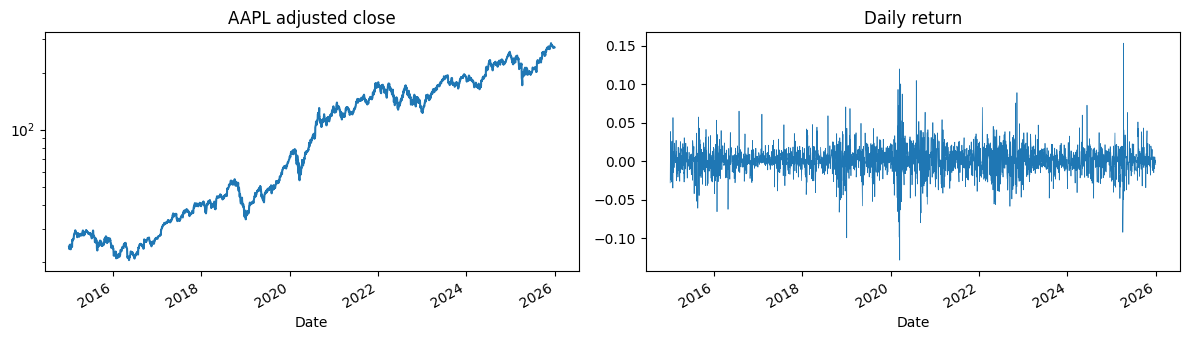

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
price.plot(ax=ax[0], title=f"{TICKER} adjusted close", logy=True)
ret.plot(ax=ax[1], title="Daily return", lw=0.5)
plt.tight_layout(); 
plt.savefig(FIG / "01_price_returns.png", dpi=120); 
plt.show()

## 2. Chronological experimental design

Observations stay in time order — **no shuffling anywhere**.

1. **Model-fitting period** = first 80% of observations. All model choices (optimizer, architecture) are made here using
   **time-series cross-validation** (`TimeSeriesSplit`, 5 expanding-window folds): each fold trains on the past and validates on the block
   that immediately follows it.
2. **Final test period** = last 20%. It is touched exactly once, in Section 6.

Inputs are standardised with a `StandardScaler` placed *inside* a pipeline, so the scaler is re-fitted on each training fold only
(no information from the validation/test data leaks into the scaling).

**Metric.** Balanced accuracy $=\tfrac12(\text{TPR}+\text{TNR})$. Because Up days are more frequent than Down days, plain accuracy
would reward a model that always says "Up". Balanced accuracy of such a model is exactly 0.5, so **0.5 is the no-skill benchmark**.

In [15]:
split = int(len(df) * (1 - TEST_FRAC))
X_fit, y_fit = X.iloc[:split], y.iloc[:split]
X_test, y_test, r_test = X.iloc[split:], y.iloc[split:], r.iloc[split:]
tscv = TimeSeriesSplit(n_splits=N_SPLITS)

print(f"Fitting period: {X_fit.index[0].date()} -> {X_fit.index[-1].date()}  ({len(X_fit)} obs, Up = {y_fit.mean():.2%})")
print(f"Test period   : {X_test.index[0].date()} -> {X_test.index[-1].date()}  ({len(X_test)} obs, Up = {y_test.mean():.2%})")
for i, (tr, va) in enumerate(tscv.split(X_fit), 1):
    print(f"  fold {i}: train {X_fit.index[tr[0]].date()}..{X_fit.index[tr[-1]].date()} | "
          f"validate {X_fit.index[va[0]].date()}..{X_fit.index[va[-1]].date()}")

Fitting period: 2015-01-20 -> 2023-10-19  (2204 obs, Up = 52.81%)
Test period   : 2023-10-20 -> 2025-12-31  (551 obs, Up = 54.63%)
  fold 1: train 2015-01-20..2016-07-06 | validate 2016-07-07..2017-12-18
  fold 2: train 2015-01-20..2017-12-18 | validate 2017-12-19..2019-06-06
  fold 3: train 2015-01-20..2019-06-06 | validate 2019-06-07..2020-11-17
  fold 4: train 2015-01-20..2020-11-17 | validate 2020-11-18..2022-05-04
  fold 5: train 2015-01-20..2022-05-04 | validate 2022-05-05..2023-10-19


## 3. Neural network and optimizer comparison

**Model** (scikit-learn `MLPClassifier`):

$$\hat p_t = \sigma\!\big(w_3^\top\, \mathrm{ReLU}(W_2\, \mathrm{ReLU}(W_1 x_t + b_1) + b_2) + b_3\big)$$

- two hidden layers, **32 and 16 neurons** (baseline), ReLU activation — simple, avoids vanishing gradients;
- logistic (sigmoid) output → $\hat p_t = P(y_t = 1 \mid x_t)$; class prediction $\hat y_t = \mathbb 1\{\hat p_t > 0.5\}$;
- objective: **binary cross-entropy (log loss)** plus a small L2 penalty (`alpha = 1e-4`, sklearn default).

**Optimizers** — all three are built into scikit-learn, so no substitution is needed:

| solver | what it is | iteration counter `n_iter_` means |
|---|---|---|
| `sgd`   | mini-batch stochastic gradient descent (batch 200, lr 0.01, momentum 0.9) | epochs (passes over the data) |
| `adam`  | adaptive-moment SGD (lr 0.001) | epochs |
| `lbfgs` | full-batch quasi-Newton method (limited-memory BFGS) | L-BFGS iterations |

Note: sklearn's `sgd` uses mini-batches with momentum, the standard practical form of SGD (not single-sample "pure" SGD).
L-BFGS uses the full training set per step, so its iterations are not directly comparable to SGD/Adam epochs — we therefore also report wall-clock time.
All solvers stop at `MAX_ITER = 300` or when the training loss stops improving by more than `tol = 1e-4` for 10 consecutive epochs.

The helper below runs time-series CV for any model and reports exactly the quantities the task asks for. It is reused for every comparison (DRY).

In [5]:
def make_model(hidden=(32, 16), solver="adam", **kw):
    '''Standardise inputs -> MLP. Only `hidden` and `solver` change between experiments.'''
    if solver == "sgd":
        kw = {"learning_rate_init": 0.01, "momentum": 0.9, **kw}
    mlp = MLPClassifier(hidden_layer_sizes=hidden, activation="relu", solver=solver,
                        max_iter=MAX_ITER, random_state=SEED, **kw)
    return make_pipeline(StandardScaler(), mlp)


def cv_report(models):
    '''Time-series CV for a dict {name: model}; returns one summary row per model.'''
    rows = {}
    for name, model in models.items():
        t0 = time.perf_counter()
        cv = cross_validate(model, X_fit, y_fit, cv=tscv, scoring="balanced_accuracy",
                            return_train_score=True, return_estimator=True)
        rows[name] = {
            "train_bal_acc": cv["train_score"].mean(),
            "val_bal_acc":   cv["test_score"].mean(),
            "val_bal_acc_std": cv["test_score"].std(),
            "time_s":        time.perf_counter() - t0,
            "mean_n_iter":   np.mean([est[-1].n_iter_ for est in cv["estimator"]]),
        }
    return pd.DataFrame(rows).T.round(4)

In [6]:
opt_table = cv_report({s: make_model(solver=s) for s in ["sgd", "adam", "lbfgs"]})
opt_table.to_csv(RES / "optimizer_comparison.csv")
best_solver = opt_table["val_bal_acc"].idxmax()
print("Selected optimizer (highest mean validation balanced accuracy):", best_solver)
opt_table

Selected optimizer (highest mean validation balanced accuracy): adam


,train_bal_acc,val_bal_acc,val_bal_acc_std,time_s,mean_n_iter
sgd,0.7249,0.4944,0.0249,1.1056,255.4
adam,0.7943,0.4981,0.0190,1.3602,294.8
lbfgs,0.9925,0.4964,0.0162,0.6016,206.8


## 4. Architecture comparison

Using the optimizer selected above, we compare the 32-16 baseline with three alternatives:
a smaller net (16-8), a wider net (64-32) and a deeper net (64-32-16). Selection is again by **mean validation** balanced accuracy only.

In [7]:
archs = {"32-16 (baseline)": (32, 16), "16-8": (16, 8), "64-32": (64, 32), "64-32-16": (64, 32, 16)}
arch_table = cv_report({name: make_model(h, best_solver) for name, h in archs.items()})
arch_table.to_csv(RES / "architecture_comparison.csv")
best_arch_name = arch_table["val_bal_acc"].idxmax()
best_hidden = archs[best_arch_name]
print("Selected architecture:", best_arch_name, "| optimizer:", best_solver)
arch_table

Selected architecture: 64-32 | optimizer: adam


,train_bal_acc,val_bal_acc,val_bal_acc_std,time_s,mean_n_iter
32-16 (baseline),0.7943,0.4981,0.0190,1.3694,294.8
16-8,0.6566,0.4987,0.0219,0.9699,270.2
64-32,0.8958,0.5071,0.0076,1.8126,277.2
64-32-16,0.9594,0.4879,0.0114,2.3310,299.4


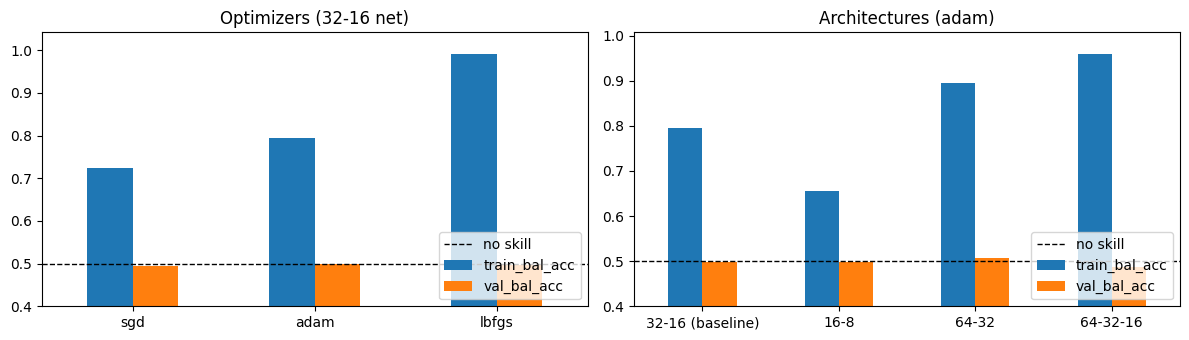

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, t, title in [(ax[0], opt_table, "Optimizers (32-16 net)"), (ax[1], arch_table, f"Architectures ({best_solver})")]:
    t[["train_bal_acc", "val_bal_acc"]].plot.bar(ax=a, rot=0, title=title)
    a.axhline(0.5, color="k", ls="--", lw=1, label="no skill"); a.set_ylim(0.4, None); a.legend(loc="lower right")
plt.tight_layout(); plt.savefig(FIG / "02_model_comparison.png", dpi=120); plt.show()

## 5. Convergence analysis (SGD and Adam)

We train the baseline 32-16 network one epoch at a time (`partial_fit`) on the training block of the **last CV fold** and, after every epoch, record

- the **training loss** (log loss + L2 penalty, `loss_`), and
- the **validation balanced accuracy** on the fold's chronological validation block.

(sklearn's built-in `early_stopping` would use a *random* validation split, which breaks time order — so we do it by hand.)

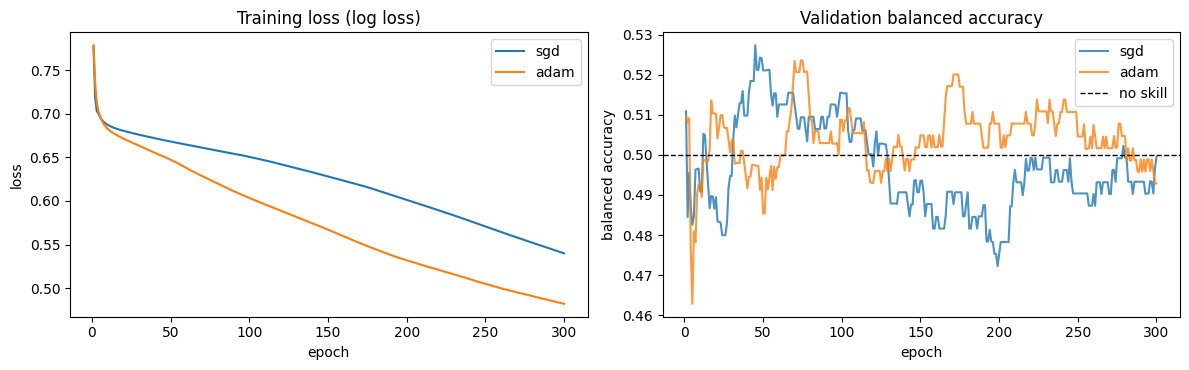

,sgd,adam
loss epoch 1,0.7771,0.7786
loss epoch 300,0.5400,0.4820
best val bal acc,0.5273,0.5236
epoch of best,45.0000,74.0000
val bal acc epoch 300,0.4994,0.4929


In [9]:
def learning_curve(solver, epochs=MAX_ITER):
    tr, va = list(tscv.split(X_fit))[-1]
    scaler = StandardScaler().fit(X_fit.iloc[tr])
    Xtr, Xva = scaler.transform(X_fit.iloc[tr]), scaler.transform(X_fit.iloc[va])
    mlp = make_model(solver=solver)[-1]                      # same MLP settings, without the scaler
    loss, score = [], []
    for _ in range(epochs):
        mlp.partial_fit(Xtr, y_fit.iloc[tr], classes=[0, 1])
        loss.append(mlp.loss_)
        score.append(balanced_accuracy_score(y_fit.iloc[va], mlp.predict(Xva)))
    return pd.DataFrame({"train_loss": loss, "val_bal_acc": score}, index=pd.RangeIndex(1, epochs + 1, name="epoch"))

curves = {s: learning_curve(s) for s in ["sgd", "adam"]}
pd.concat(curves, axis=1).to_csv(RES / "convergence_curves.csv")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for s, c in curves.items():
    c["train_loss"].plot(ax=ax[0], label=s)
    c["val_bal_acc"].plot(ax=ax[1], label=s, alpha=0.8)
ax[0].set(title="Training loss (log loss)", ylabel="loss")
ax[1].axhline(0.5, color="k", ls="--", lw=1, label="no skill")
ax[1].set(title="Validation balanced accuracy", ylabel="balanced accuracy")
for a in ax: a.legend()
plt.tight_layout(); plt.savefig(FIG / "03_convergence.png", dpi=120); plt.show()

pd.DataFrame({s: {"loss epoch 1": c.train_loss.iloc[0], f"loss epoch {MAX_ITER}": c.train_loss.iloc[-1],
                  "best val bal acc": c.val_bal_acc.max(), "epoch of best": c.val_bal_acc.idxmax(),
                  f"val bal acc epoch {MAX_ITER}": c.val_bal_acc.iloc[-1]} for s, c in curves.items()}).round(4)

## 6. Final model evaluation on the untouched test period

The selected model (architecture + optimizer chosen only from validation results) is re-fitted on the **whole fitting period**
and evaluated **once** on the test period. As a reference we also show the naive "always Up" rule.

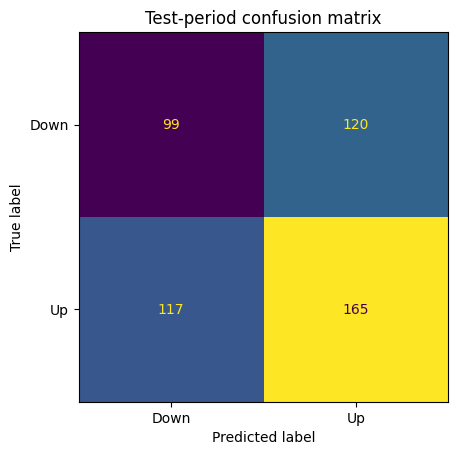

,"NN 64-32, adam",Always Up
accuracy,0.5269,0.5629
balanced_accuracy,0.5186,0.5000
share predicted Up,0.5689,1.0000


In [10]:
final = make_model(best_hidden, best_solver).fit(X_fit, y_fit)
p_test = pd.Series(final.predict_proba(X_test)[:, 1], index=X_test.index)
yhat = (p_test > 0.5).astype(int)

test_table = pd.DataFrame({
    f"NN {best_arch_name}, {best_solver}": [accuracy_score(y_test, yhat), balanced_accuracy_score(y_test, yhat), yhat.mean()],
    "Always Up":                          [y_test.mean(), 0.5, 1.0],
}, index=["accuracy", "balanced_accuracy", "share predicted Up"]).round(4)
test_table.to_csv(RES / "test_metrics.csv")

cm = confusion_matrix(y_test, yhat)
pd.DataFrame(cm, index=["true Down", "true Up"], columns=["pred Down", "pred Up"]).to_csv(RES / "confusion_matrix.csv")
ConfusionMatrixDisplay(cm, display_labels=["Down", "Up"]).plot(colorbar=False)
plt.title("Test-period confusion matrix"); plt.savefig(FIG / "04_confusion_matrix.png", dpi=120); plt.show()
test_table

## 7. Investment strategy

- **Buy and hold:** $R^{BH}_t = r_t$.
- **NN directional strategy:** hold the stock only when the network predicts Up, otherwise hold cash (zero return):
  $s_t = \mathbb 1\{\hat p_t > 0.5\}$, $\;R^{NN}_t = s_t\, r_t$.
- **After transaction costs:** each change of position (buy or sell) costs $c = 10$ bp:
  $R^{NN,c}_t = s_t\, r_t - c\,|s_t - s_{t-1}|$ (we assume the strategy starts in cash, so entering costs $c$ too).

Because $s_t$ depends only on returns up to $t-1$, the position can be set at the previous close — no look-ahead.
Growth of one monetary unit: $W_T = \prod_t (1 + R_t)$.

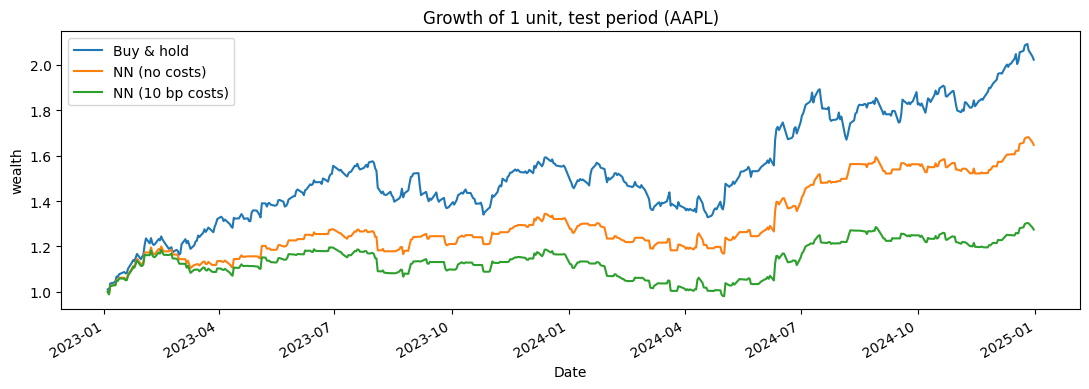

,final wealth (1 →),ann. return,ann. volatility,Sharpe (rf=0),max drawdown,time in market,# trades
Buy & hold,2.0233,0.4254,0.2135,1.7673,-0.1661,1.000000,1.0
NN (no costs),1.6476,0.2855,0.1684,1.5752,-0.1303,0.568862,257.0
NN (10 bp costs),1.2742,0.1296,0.1689,0.8055,-0.1803,0.568862,257.0


In [11]:
pos = yhat
trades = pos.diff().fillna(pos.iloc[0]).abs()           # 1 whenever we buy or sell
strategies = pd.DataFrame({
    "Buy & hold":          r_test,
    "NN (no costs)":       pos * r_test,
    f"NN ({COST*1e4:.0f} bp costs)": pos * r_test - COST * trades,
})


def perf(R, days=252):
    '''Standard performance summary of a daily return series.'''
    wealth = (1 + R).cumprod()
    return pd.Series({
        "final wealth (1 →)": wealth.iloc[-1],
        "ann. return":        wealth.iloc[-1] ** (days / len(R)) - 1,
        "ann. volatility":    R.std() * np.sqrt(days),
        "Sharpe (rf=0)":      R.mean() / R.std() * np.sqrt(days),
        "max drawdown":       (wealth / wealth.cummax() - 1).min(),
    })


perf_table = strategies.apply(perf).T.round(4)
perf_table["time in market"] = [1, pos.mean(), pos.mean()]
perf_table["# trades"] = [1, trades.sum(), trades.sum()]
perf_table.to_csv(RES / "strategy_performance.csv")

(1 + strategies).cumprod().plot(figsize=(11, 4), title=f"Growth of 1 unit, test period ({TICKER})")
plt.ylabel("wealth"); plt.tight_layout(); plt.savefig(FIG / "05_strategy_growth.png", dpi=120); plt.show()
perf_table

## 8. Conclusions

*(Numbers below come from the executed run with the settings in Section 0 and `SEED = 42`.)*

**Data.** AAPL, 2015-01-20 → 2024-12-31, 2,505 daily observations; 53.3% Up / 46.7% Down. Fitting period 2015–2022 (2,004 obs), test period 2023–2024 (501 obs, 56.3% Up).

**Optimizers (32-16 net, 5-fold time-series CV).**
All three fit the *training* data well above chance: L-BFGS ≈ 0.99, Adam ≈ 0.79, SGD ≈ 0.72 training balanced accuracy.
But mean *validation* balanced accuracy is ≈ 0.50 for all of them (SGD 0.494, Adam 0.498, L-BFGS 0.496), i.e. no skill.
L-BFGS is the fastest here (small data set, full-batch quasi-Newton) and the strongest at memorising noise.
SGD and Adam usually hit the 300-epoch cap (mean `n_iter_` ≈ 255 and 295), so the loss is still slowly falling when they stop.
Adam has the highest validation score, so it is selected — but the differences (≈0.004) are much smaller than the fold-to-fold standard deviation (≈0.02), so this choice is essentially arbitrary.

**Architectures (Adam).** Larger networks overfit more (training bal. acc. 0.66 → 0.96 from 16-8 to 64-32-16) without better validation results.
64-32 gives the best mean validation score (0.507) and is selected; the deeper 64-32-16 is the worst (0.488).
Again, all differences are within about one standard deviation of zero skill.

**Convergence.** For both SGD and Adam the training loss falls steadily (0.78 → 0.54 for SGD, 0.78 → 0.48 for Adam; Adam descends faster).
Validation balanced accuracy peaks early (SGD ≈ 0.53 at epoch ≈ 45, Adam ≈ 0.52 at epoch ≈ 74) and then drifts back to ≈ 0.50.
This is the classic overfitting pattern: after the first few dozen epochs the network fits noise in past returns, not a repeatable signal.
(Picking the "best" epoch from one fold's curve would itself be overfitting the validation data, so we did not do it.)

**Final test (untouched 2023–2024).** Accuracy 0.527, balanced accuracy 0.519. The naive "always Up" rule has a *higher* accuracy (0.563) because the test period was a bull market.
A balanced accuracy of 0.519 on 501 days is only ≈ 0.8 standard errors above 0.5 (SE ≈ 0.5/√501 ≈ 0.022) — **not statistically meaningful**.
Conclusion: lagged returns alone give no meaningful out-of-sample predictive improvement for AAPL, consistent with weak-form market efficiency.

**Investment strategy.** Buy and hold turned 1 into 2.02 (Sharpe 1.77).
The NN strategy was in the market only 57% of days: before costs it turned 1 into 1.65 (Sharpe 1.58) with lower volatility and a smaller drawdown — mostly because it simply holds less stock, not because it times the market well.
It changed position 257 times in 501 days; at 10 bp per trade costs cut the result to 1.27 (Sharpe 0.81) and made the drawdown worse than buy and hold.
**Buy and hold dominates the neural-network strategy both before and after transaction costs.**

**Limitations.** One stock, one seed and one test window; results can change with the seed or period. Only lagged returns are used (by design); volume, market-wide and macro variables might add information, but that is outside this task.